# Encoder-Only Model

In this notebook, an `encoder-only` model, in poarticular `Bert Base Multilingual Uncased`, is used to decide if a tweet regarding politic themes has hate content or not. 

To reach this target, the BERT model is used to retrieve the contextual embeddings of the tweet that, feed a `Neural Head` which eventually 

decide for **Class 0** (Not Hate Speech) and **Class 1** (Hate Speech).

The hyperparameters of the training phase, togheter with the `Feed Forward Network` ones, are chosen through a **Grid Search** 

which compares the macro F1 scores on the validation sets.

At the end, the best model is evaluated on the test dataset, also in this case, using the **Macro F1-Score** metric, below reported

$$ F1_{avg} = \frac{F1_{class0} + F1_{class1}}{2} $$

The dataset used for this task is the `PolicyCOrpusXL` ***F Celli et Al., (2021)***, used in the work ***M Lai et Al., (2023)***.

The dataset consists of a **textual part** i.e., the Tweet, a reference to the user (anonymized) the label and the dataset which the tweet belongs to (politics or religious) 

and, of a **contextual data** that has not been used.




## 0. Common code

In this section of the notebook, there is the code related to:

- Global constants
- Imports common to every cell
- Loading of the dataset

In [1]:
# 0.1 Constant
DATASET_DIR         =       "./Dataset/"
TRAIN_DATASET       =       "training_textual.csv" 
TEST_DATASET        =       "test_textual_gold.csv" 
MODEL_NAME          =       "bert-base-multilingual-uncased"
MODEL_TASK          =       "feature-extraction"
VAL_FRACTION        =       0.15
RANDOM_SEED         =       42
EMBEDDING_DIM       =       768
NUM_CLASSES         =       2 


# 0.2 Global imports
import pandas as pd
import numpy as np

In [2]:
# 1. CSV Read
train_df = pd.read_csv(DATASET_DIR + TRAIN_DATASET)
test_df = pd.read_csv(DATASET_DIR + TEST_DATASET)
train_df

,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics
2,817917484817935,Il #m5s ha votato contro le #unionicivili addu...,1,training_politics
3,172580609652325,La #Lega e il #m5s stanno dando a bere all'opi...,0,training_politics
4,145836038456701,Che cosa cambia questa #legge? Caro @667517147...,0,training_politics
...,...,...,...,...
5595,715670659156960,#Covid. #Draghi non fare come #Conte. La #poli...,0,training_politics
5596,512309888296620,"Cina, «128mila euro a neonato»: la proposta pe...",0,training_politics
5597,887061502405620,@401560935985106 @507718538254873 @28429789767...,1,training_politics
5598,531900858879345,"Trasporto pubblico, Simeone nominato consiglie...",0,training_politics


## 1. Data Preparation

In this section of the notebook, the dataset is explored, and pre-processed with the necessary clean-up of the tweets

In [3]:
# 0. Imports
from collections import Counter
from typing import List, Dict
from pprint import pprint

### 1.1. Dataset exploration

From the whole dataset, only the tweets belonging to the `politics` subset have to be preserved.

In [4]:
# 1. Remove the data that are not labeled "training_politics" or "test_politics"
allowed_labels = ["training_politics", "test_politics"]
train_politics_df = train_df[train_df["dataset"].isin(allowed_labels)].reset_index(drop=True)
test_politics_df = test_df[test_df["dataset"].isin(allowed_labels)].reset_index(drop=True)
train_politics_df

,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics
2,817917484817935,Il #m5s ha votato contro le #unionicivili addu...,1,training_politics
3,172580609652325,La #Lega e il #m5s stanno dando a bere all'opi...,0,training_politics
4,145836038456701,Che cosa cambia questa #legge? Caro @667517147...,0,training_politics
...,...,...,...,...
5595,715670659156960,#Covid. #Draghi non fare come #Conte. La #poli...,0,training_politics
5596,512309888296620,"Cina, «128mila euro a neonato»: la proposta pe...",0,training_politics
5597,887061502405620,@401560935985106 @507718538254873 @28429789767...,1,training_politics
5598,531900858879345,"Trasporto pubblico, Simeone nominato consiglie...",0,training_politics


In [5]:
# 2. Statistics
train_hs_count = (train_politics_df['label'] == 1).sum()
train_nhs_count = (train_politics_df['label'] == 0).sum()

print(f"The training set has {train_politics_df.shape[0]} elements, \
    {train_hs_count} of class Hate Speech \
    and {train_nhs_count} of class Not Hate Speech")
    
print(f"The test set has {test_politics_df.shape[0]} elements, \
    { (test_politics_df['label'] == 1).sum()} of class Hate Speech \
    and {(test_politics_df['label'] == 0).sum()} of class Not Hate Speech")

The training set has 5600 elements,     2144 of class Hate Speech     and 3456 of class Not Hate Speech
The test set has 1400 elements,     700 of class Hate Speech     and 700 of class Not Hate Speech


<Axes: xlabel='label'>

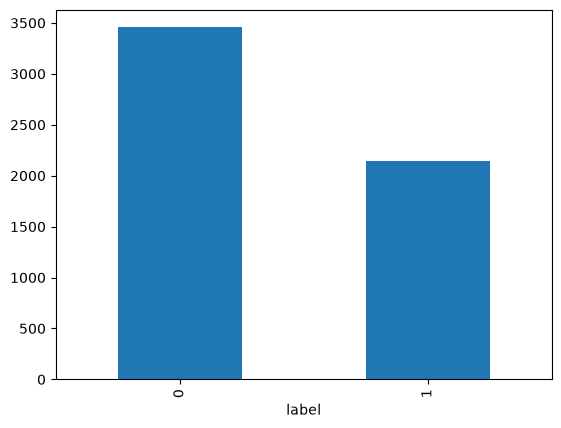

In [6]:
# 3.1 Look graphically to the balancing of the classes in training set
train_politics_df.groupby(['label']).size().plot.bar()

From the **bar plot** of the training set respect to the classes, it is possible to notice a little unbalance betrween 

the **Not Hate Speech** class (3456 samples) and the **Hate Speech** one (2144 samples) with a ratio

$$ \frac{NHS}{HS} = 1.61 $$

As a consequence, an augmentation technique for the **HS** class samples could be take in consideration.


<Axes: xlabel='label'>

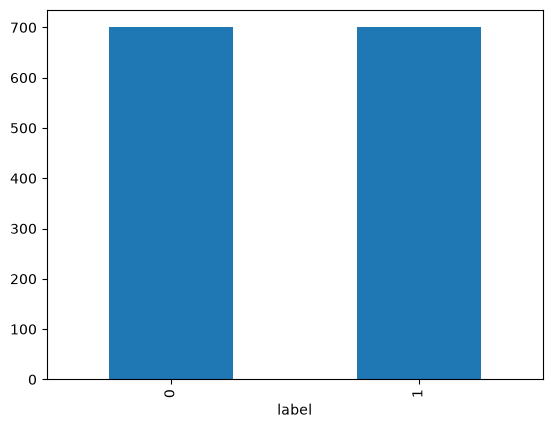

In [7]:
# 3.2 Look graphically to the balancing of the classes in test set
test_politics_df.groupby(['label']).size().plot.bar()

In contrast, in the test set the classes are perfecly balanced. 

Thus, if the augmentation has been done, it shall be performed before the extraction of the validation set, since, the test set distribution lead to consider 

the tweets of the real world balanced.

In [8]:
# 4.1. Function to count non alpha-numeric characters in the dataset
def count_special_characters(
    texts_i: pd.Series | List[str],
    ignore_whitespace_i: bool = True,
) -> Dict[str, int]:
    """
    Search for non-alphanumeric ("special") characters (e.g., "@", "#", punctuation,
    emojis) across a dataset of texts and count their occurrences.

    Parameters
    ----------
    texts_i : pd.Series | List[str]
        Collection of text strings from the dataset.
    ignore_whitespace_i : bool
        If True, spaces, tabs, and newlines are excluded from the count (default: True).

    Return
    ------
    special_chars_o: Dict[str, int]
        Dictionary mapping each non-alphanumeric character to its frequency,
        sorted in descending order of count.
    """
    char_counter: Counter = Counter()

    for text in texts_i:
        if not isinstance(text, str):
            continue
        for char in text:
            if char.isalnum():
                continue
            if ignore_whitespace_i and char.isspace():
                continue
            char_counter[char] += 1

    return char_counter

It is also usefull to inspect the dataset for special characters (i.e. non-alphanumeric and emoji) in order to decide 

how to treat these in the next steps. 

In [9]:
# 4.2. Counting special characters in the training set
train_cnt = count_special_characters(train_politics_df['anonymized_text'])

# 4.3. Counting special characters in the test set
test_cnt = count_special_characters(test_politics_df['anonymized_text'])

print(f"There are {len(train_cnt)} special characters in the training set and, {len(test_cnt)} special characters in the test set")
print(f"The most common special characters in the training set are:")
pprint(train_cnt.most_common())
print(f"The most common special characters in the test set are:")
pprint(test_cnt.most_common())

There are 260 special characters in the training set and, 144 special characters in the test set
The most common special characters in the training set are:
[('#', 22427),
 ('.', 9240),
 (',', 5030),
 ('@', 3613),
 ("'", 1766),
 ('[', 1619),
 (']', 1618),
 ('!', 1586),
 ('?', 1474),
 ('"', 1257),
 (':', 1117),
 ('’', 674),
 (')', 503),
 ('-', 456),
 ('(', 452),
 ('“', 290),
 ('”', 285),
 ('_', 209),
 (';', 147),
 ('%', 137),
 ('/', 127),
 ('+', 121),
 ('🤣', 103),
 ('*', 93),
 ('️', 88),
 ('😂', 87),
 ('&', 51),
 ('🤡', 50),
 ('💩', 46),
 ('€', 40),
 ('🏻', 40),
 ('🤔', 38),
 ('😡', 38),
 ('👇', 34),
 ('«', 33),
 ('»', 32),
 ('🤬', 32),
 ('🇮', 31),
 ('🇹', 31),
 ('\u200d', 30),
 ('👏', 29),
 ('🤮', 28),
 ('😁', 25),
 ('‘', 23),
 ('=', 21),
 ('🔴', 19),
 ('…', 18),
 ('•', 17),
 ('♂', 16),
 ('🤦', 16),
 ('🤐', 16),
 ('🖕', 16),
 ('🙄', 14),
 ('👎', 14),
 ('☠', 14),
 ('🔵', 13),
 ('😷', 13),
 ('➡', 12),
 ('‼', 12),
 ('\u2066', 12),
 ('\u2069', 12),
 ('🌶', 12),
 ('😉', 11),
 ('°', 10),
 ('💪', 10),
 ('😅', 10),
 

As expected, the most common character is the `#` for the hashtag, then there is the `@` for the mentions and finally a lot of `emoji`

### 1.2. Tweet clean-up

It has been decided to remove all the `mentions` (code starting with a "@") and, also, to remove the `stop words` since 

they do not have so much information content. 

For the mention removal a simple **regex** is used while, to remove the stop words an `NLTK` pipeline is put in place. In this case:

- Firstly the sentences are tokenized to separate the punctuation
- Then the stop words are removed
- Finally the sentence is joined again in a string

In [10]:
# 0. Imports
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
# pyrefly: ignore [missing-import]
import emoji

# 0.1 Download the sopwords not yet present
try:
    nltk.data.find('corpora/stopwords')
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('stopwords')  
    nltk.download('punkt_tab')

In [11]:
# 1. Function to clean-up the tweets
def sentence_cleanup(sentence_i: str, stop_words_i: list[str]) -> str:
    """
    Remove @mentions, collapse multiple spaces into a single space, 
    remove stopwords and convert to lowercase.

    Parameters
    ----------
    sentence_i : str
        Input sentence to clean.
    stop_words_i : list[str]
        List of the stopwords to be removed

    Return
    ------
    cleaned_sentence_o: str
        Cleaned sentence
    """
    tmp_result = re.sub(r"@\w+", "", sentence_i)
    tmp_result = re.sub(r"\s+", " ", tmp_result).strip().lower()
    tokenized_sentence = word_tokenize(language='italian', text=tmp_result)
    cleaned_sentence_o = [word for word in tokenized_sentence if word not in stop_words_i]
    return " ".join( cleaned_sentence_o )



In [12]:
# 2. Clean-up train and test dataset
# 2.1 Train dataset
cleanup_sentences = []
stop_words = stopwords.words('italian')
for rows in range( train_politics_df.shape[0] ):
    cleanup_sentences.append( 
        sentence_cleanup(sentence_i=train_politics_df.iloc[rows]['anonymized_text'],  stop_words_i=stop_words) 
    )
train_politics_df['anonymized_text'] = cleanup_sentences

# 2.2 Test dataset
cleanup_sentences.clear()
for rows in range( test_politics_df.shape[0] ):
    cleanup_sentences.append( 
        sentence_cleanup(sentence_i=test_politics_df.iloc[rows]['anonymized_text'], stop_words_i=stop_words) 
    )
test_politics_df['anonymized_text'] = cleanup_sentences

train_politics_df

,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,"tutte denunce beccando , salvini rischia far a...",1,training_politics
1,360042217507605,# prescrizione : ( t ) re magi trovato ’ accor...,0,training_politics
2,817917484817935,# m5s votato # unionicivili adducendo scuse ve...,1,training_politics
3,172580609652325,# lega # m5s dando bere all'opinione pubblica ...,0,training_politics
4,145836038456701,cosa cambia # legge ? caro # decretoinsicurezz...,0,training_politics
...,...,...,...,...
5595,715670659156960,# covid . # draghi fare # conte . # politica n...,0,training_politics
5596,512309888296620,"cina , « 128mila euro neonato » : proposta spi...",0,training_politics
5597,887061502405620,anch'io leggo commenti . na # vergogna oppure ...,1,training_politics
5598,531900858879345,"trasporto pubblico , simeone nominato consigli...",0,training_politics


For what concerns the **emoji** handling, it has been decided to convert them in a textual description (e.g.  😡 -> ***faccia_imbronciata***) since,

to make BERT generating embeddings for emoji, it is necessary to fine tune it. 

In [13]:
# 3. Convert the emoji in text description
# 3.1. Train set
res = []
for rows in range( train_politics_df.shape[0] ):
    res.append( 
        emoji.demojize( train_politics_df.iloc[rows]['anonymized_text'], language='it', delimiters=(" ", " ") )
    )
train_politics_df['anonymized_text'] = res

# 3.2. Test set
res.clear()
for rows in range( test_politics_df.shape[0] ):
    res.append( 
        emoji.demojize( test_politics_df.iloc[rows]['anonymized_text'], language='it', delimiters=(" ", " ") )
    )
test_politics_df['anonymized_text'] = res

In [14]:
# 4. Look the result of the convertion
# 4.2. Counting special characters in the training set
train_cnt = count_special_characters(train_politics_df['anonymized_text'])

# 4.3. Counting special characters in the test set
test_cnt = count_special_characters(test_politics_df['anonymized_text'])

print(f"There are {len(train_cnt)} special characters in the training set and, {len(test_cnt)} special characters in the test set")
print(f"The most common special characters in the training set are:")
pprint(train_cnt.most_common())
print(f"The most common special characters in the test set are:")
pprint(test_cnt.most_common())

# 4.4. Search for the "faccia_imbronciata"
emoji_cnt = 0
for rows in range( train_politics_df.shape[0] ):
    if "faccina_con_lacrime_di_gioia" in train_politics_df.iloc[rows]['anonymized_text']:
        emoji_cnt += 1

print( "Number of 'faccina_con_lacrime_di_gioia: ", emoji_cnt)

There are 51 special characters in the training set and, 40 special characters in the test set
The most common special characters in the training set are:
[('#', 22427),
 ('.', 9240),
 (',', 5030),
 ("'", 2988),
 ('_', 2574),
 ('[', 1619),
 (']', 1618),
 ('!', 1586),
 ('?', 1474),
 ('`', 1298),
 (':', 1117),
 ('’', 692),
 (')', 503),
 ('-', 456),
 ('(', 452),
 ('“', 290),
 ('”', 285),
 (';', 147),
 ('%', 137),
 ('/', 127),
 ('+', 121),
 ('*', 93),
 ('&', 51),
 ('€', 40),
 ('«', 33),
 ('»', 32),
 ('‘', 23),
 ('=', 21),
 ('…', 18),
 ('•', 17),
 ('\u2066', 12),
 ('\u2069', 12),
 ('°', 10),
 ('|', 10),
 ('َ', 6),
 ('@', 5),
 ('–', 4),
 ('《', 3),
 ('》', 3),
 ('ُ', 3),
 ('~', 3),
 ('—', 2),
 ('^', 2),
 ('{', 2),
 ('}', 2),
 ('→', 2),
 ('·', 2),
 ('×', 2),
 ('„', 1),
 ('￼', 1),
 ('\\', 1)]
The most common special characters in the test set are:
[('#', 5672),
 ('.', 2268),
 (',', 1225),
 ("'", 760),
 ('_', 663),
 ('!', 430),
 ('?', 409),
 ('[', 400),
 (']', 400),
 ('`', 278),
 (':', 269),
 ('’

### 1.3. Data augmentation

As said, the **NHS** class has the 38% of samples more than the **NHS** one.

As a consequence, the best macro F1 scores reached before the data augmentation was 0.77, due to a lot of **HS** samples

misclassified as **NHS** ones. 

Thus, it has been decided to increase the samples of **HS** till the equality with **NHS**. The technique used is the generations of new sentences

from randomly sampled ones (without insertion), made by synonyms. 

In [15]:
# 0. Imports
from nltk.corpus import wordnet as wn 
import random
random.seed(42)

for resource in ("corpora/wordnet", "corpora/omw-2.0"):
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(resource.split("/")[1], quiet=True)

In [16]:
# 1. Funtion to generate a synonym sentence
def generate_synonym_sentence(
    sentence_i: str,
    lang_i: str = "ita",
    replace_prob_i: float = 1.0,
) -> str:
    """
    Create a new sentence by replacing words in the input sentence with WordNet synonyms.

    Parameters
    ----------
    sentence_i : str
        Input sentence to augment with synonyms.
    lang_i : str
        ISO 639-3 language code for WordNet (e.g., "ita" for Italian, "eng" for English;
        default: "ita").
    replace_prob_i : float
        Probability (0.0 to 1.0) of replacing each word that has at least one synonym
        (default: 1.0).

    Return
    ------
    new_sentence_o: str
        New sentence with words replaced by randomly chosen WordNet synonyms.
    """

    tokenizer_lang = "italian" if lang_i == "ita" else "english"
    tokens = word_tokenize(sentence_i, language=tokenizer_lang)
    new_tokens: List[str] = []

    for token in tokens:
        if token.isalpha() and random.random() <= replace_prob_i:
            synonyms = set()
            for synset in wn.synsets(token.lower(), lang=lang_i):
                for lemma in synset.lemmas(lang=lang_i):
                    candidate = lemma.name().replace("_", " ").lower()
                    if candidate != token.lower():
                        synonyms.add(candidate)

            if synonyms:
                new_tokens.append(random.choice(list(synonyms)))
                continue

        new_tokens.append(token)

    new_sentence_o = " ".join(new_tokens)
    return new_sentence_o

In [17]:
# 2. Data augmentation till the equality of the 2 classes
train_hs_sentences = (train_politics_df[
    train_politics_df['label'] == 1
].reset_index(drop=True))['anonymized_text']

used_idx = []
new_sentences = []
idx = 0
for _ in range(train_nhs_count - train_hs_count):
    while(idx in used_idx):
        idx = random.randint(0, train_hs_sentences.shape[0] - 1)
    used_idx.append(idx)
    new_sentences.append(
        generate_synonym_sentence( train_hs_sentences[idx], replace_prob_i=0.1 )
    )
    # print(f"{idx}: {new_sentences[-1]}")

len(new_sentences)


1312

<Axes: xlabel='label'>

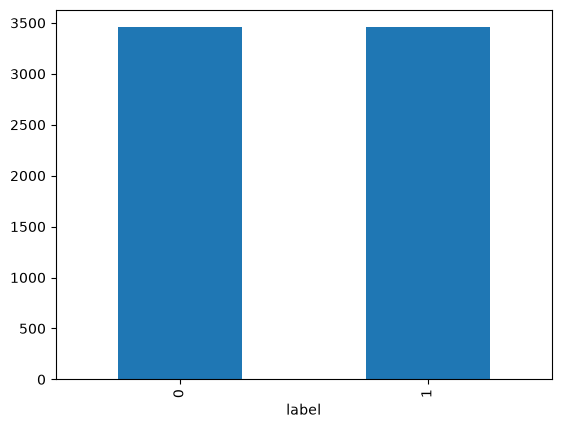

In [18]:
# 3.1. Regenerating the training dataframe
new_rows_df = pd.DataFrame({
    "anonymized_tweet_id": [None] * len(new_sentences),
    "anonymized_text": new_sentences,
    "label": [1] * len(new_sentences),
    "dataset": ["training_politics"] * len(new_sentences),
})
train_politics_df = pd.concat(
    [train_politics_df, new_rows_df],
    ignore_index=True,
)

# 3.2. Look at the distribution
train_politics_df.groupby(['label']).size().plot.bar()

## 2. Model

### 2.1. BERT-Like model

In this section a `BERT` `Transformer` is used as `encoder-only` model. 

After retrieving the model from **Hugging Face** a pipeline for the task `feature extraction` is instantiated. 

This makes simple to extract the embedding of the token `[CLS]` from the last layer of the Transformer to be 

used in the following of the notebook for the sentiment classification task.

In [19]:
# 0. Imports
from transformers import BertTokenizer, BertModel
from transformers import pipeline

/Users/calogeroforte/work/Python_work_area/Hate_Speech_Detection/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 22:43:05.916000 5438 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [20]:
# 1. Retrieve the tokenizer and the model
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
model = BertModel.from_pretrained(MODEL_NAME)
model

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16638.75it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(105879, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p

In [21]:
# 2. Create a pipeline to get the last hidden state (thus the embeddings)
feature_extraction_pipeline = pipeline( task=MODEL_TASK, model=model, tokenizer=tokenizer )

### 2.2. Classification head

A `Feed-Forward Neural Network` is used as Neural Head for the classification of the tweets. 

The framework used to design this network is **PyTorch** with a class **HateSpeechClassifier** which inherits from ***nn.Module***.

The architecture consists of:

1. Projection ***embeddings*** -> ***hidden state***
2. ***normalization*** layer
3. ***dropout*** layer
4. ***ReLU*** activation function
5. Projection ***activation*** -> ***classes***

Notice that the the number of hidden layers is an hyperparameters which can be decided by the **Grid Search** thus, 

the points (2), (3) and (4) can be repeated more than one time.

In [22]:
# 0. Imports
import torch
from torch import nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from transformers import Pipeline
from typing import Tuple, Optional

Create the dataset class.

Notice that the **[CLS]** embedding is computed at this point, using the **Pipeline** object,

in order to do not wast time during the grid search. 

In [23]:
# 1. Dataset class
class HateSpeechDataset(Dataset):
    """
    PyTorch Dataset that extracts BERT [CLS] embeddings from tweet texts
    using a Hugging Face feature-extraction pipeline and pairs them with labels.

    Parameters
    ----------
    texts_i : pd.Series | List[str]
        Collection of cleaned tweet strings.
    labels_i : pd.Series | List[int]
        Collection of binary labels (1 = Hate Speech, 0 = Not Hate Speech).
    pipeline_i : Pipeline
        Hugging Face feature-extraction pipeline instantiated with BERT.

    Return
    ------
    None
    """

    def __init__(
        self,
        texts_i: pd.Series | List[str],
        labels_i: pd.Series | List[int],
        pipeline_i: Pipeline,
    ) -> None:
        super().__init__()
        texts_list = list(texts_i)
        labels_list = list(labels_i)

        embeddings_list: List[torch.Tensor] = []
        with torch.no_grad():
            for text in tqdm(texts_list, desc="Extracting BERT embeddings"):
                # pipeline output shape for a single string: (1, seq_len, hidden_dim)
                # Take the [CLS] token embedding at index 0 (last hidden state of [CLS])
                output_tensor = pipeline_i(
                    text,
                    return_tensors=True,
                    truncation=True,
                    max_length=512,
                )
                cls_embedding = output_tensor[0, 0, :].detach().cpu() # TODO: To check the indexes
                embeddings_list.append(cls_embedding)

        self.embeddings = torch.stack(embeddings_list)
        self.labels = torch.tensor(labels_list, dtype=torch.long)

    def __len__(self) -> int:
        """
        Return the total number of samples in the dataset.

        Parameters
        ----------
        None

        Return
        ------
        length_o: int
            Number of samples in the dataset.
        """
        return len(self.labels)
        

    def __getitem__(self, idx_i: int) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Retrieve the embedding and label at the given index.

        Parameters
        ----------
        idx_i : int
            Index of the sample to retrieve.

        Return
        ------
        sample_o: Tuple[torch.Tensor, torch.Tensor]
            Tuple containing (embedding_tensor, label_tensor).
        """
        return (self.embeddings[idx_i], self.labels[idx_i])

In [24]:
# 2. Neural Head model class
class HateSpeechClassifier(nn.Module):
    """
    Feed-forward neural network used as a classification head on top of BERT embeddings.
    Each hidden block consists of:
    Linear -> BatchNorm1d (1D Normalization) -> Dropout -> ReLU,
    repeated `num_hidden_layers_i` times, followed by a final Linear layer to classes.

    Parameters
    ----------
    embedding_dim_i : int
        Dimension of the input BERT embeddings (e.g., 768).
    hidden_dim_i : int
        Number of units in each hidden layer (e.g., 768, 384, 192).
    num_hidden_layers_i : int
        Number of hidden blocks to stack (e.g., 1 or 2).
    dropout_i : float
        Dropout probability for each Dropout layer.
    num_classes_i : int
        Number of output classes (default: 2).

    Return
    ------
    None
    """

    def __init__(
        self,
        embedding_dim_i: int = 768,
        hidden_dim_i: int = 768,
        num_hidden_layers_i: int = 1,
        dropout_i: float = 0.1,
        num_classes_i: int = 2,
    ) -> None:
        super().__init__()
        layers: List[nn.Module] = []
        in_features = embedding_dim_i

        for _ in range(num_hidden_layers_i):
            # Projection from embeddings to hidden layer
            layers.append(nn.Linear(in_features, hidden_dim_i))
            # Normalization
            layers.append(nn.BatchNorm1d(hidden_dim_i))
            # Dropout
            layers.append(nn.Dropout(dropout_i))
            # ReLu activation
            layers.append(nn.ReLU())
            in_features = hidden_dim_i

        layers.append(nn.Linear(hidden_dim_i, num_classes_i))
        # Create the model as a sequential passing the
        # exploded list of layers
        self.classifier = nn.Sequential(*layers)

    def forward(self, embeddings_i: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the classification head.

        Parameters
        ----------
        embeddings_i : torch.Tensor
            Batch of input BERT embeddings of shape (batch_size, embedding_dim).

        Return
        ------
        logits_o: torch.Tensor
            Output class logits of shape (batch_size, num_classes).
        """
        return self.classifier(embeddings_i)

In the following there are implemented the functions for train and evaluate the neural network

in an epoch. Notice that the loss is computed as the average over the epochs (the denominator is ***len(dataloade))***

while the accuracy is computed over the samples (the denominator is ***len(dataloade.dataset)***)

The train and evaluate loop make use of support funtions to compute activations and loss, 

to support both a `multi class classification head` (with **cross entropy** and **softmax**) and 

a `binary classification head` (with **binary cross entropy** and **sigmoid**)

In [25]:
# Support functions to compute the activations
def compute_activations(
    logits_i: torch.Tensor,
    activation_fn_i: nn.Module
) -> torch.Tensor:
    """ 
    Compute the activations given the logits

    Parameters
    ----------
    logits_i: torch.Tensor
        The logits to which apply the activation function
    activation_fn_i: nn.ModuleDict
        The activation function instance.
        Supports nn.Softmax (or nn.LogSoftmax) and nn.Sigmoid
    """
    activations = activation_fn_i(logits_i)
    if isinstance(activation_fn_i, nn.Sigmoid):
        if activations.ndim == 1 or activations.size(1) == 1:
            return (activations.squeeze(-1) >= 0.5).long()
        else:
            return activations.argmax(dim=1)
    elif isinstance(activation_fn_i, (nn.Softmax, nn.LogSoftmax)):
        return activations.argmax(dim=1)
    else:
        raise ValueError(
            f"Unsupported activation_fn_i '{type(activation_fn_i).__name__}'. "
            "Expected nn.Softmax, nn.LogSoftmax, or nn.Sigmoid."
        )

# Support functions to compute the loss
def compute_loss(
    logits_i: torch.Tensor,
    loss_fn_i: nn.Module,
    batch_labels_i: Optional[torch.Tensor] = None
) -> torch.nn:
    """ 
    Compute the activations given the logits

    Parameters
    ----------
    logits_i: torch.Tensor
        The logits to which apply the activation function
    loss_fn_i: nn._Loss
        The loss function instance.
        Supports nn.CrossEntropyLoss and nn.BCEWithLogitsLoss
    """
    if isinstance(loss_fn_i, nn.CrossEntropyLoss) and batch_labels_i != None:
        return loss_fn_i(logits_i, batch_labels_i)
    elif isinstance(loss_fn_i, nn.BCEWithLogitsLoss):
        return loss_fn_i(logits_i.squeeze(-1), batch_labels_i.float())
    else:
        raise ValueError(
            f"Unsupported loss_fn_i '{type(loss_fn_i).__name__}'. "
            "Expected CrossEntropyLoss or nn.BCEWithLogitsLoss."
        )

# 3. Training epoch function
def train_epoch(
    model_i: nn.Module,
    dataloader_i: DataLoader,
    loss_fn_i: nn.Module,
    activation_fn_i: nn.Module,
    optimizer_i: torch.optim.Optimizer,
    device_i: torch.device,
) -> Tuple[float, float]:
    """
    Train the classification head for a single epoch.

    Parameters
    ----------
    model_i : nn.Module
        The neural network model to train.
    dataloader_i : DataLoader
        DataLoader providing training batches of (embeddings, labels).
    loss_fn_i : nn.Module
        Loss criterion (e.g., nn.CrossEntropyLoss).
    activation_fn_i: nn.Module
        The activation function to use to compute the probabilities of the output classes.
    optimizer_i : torch.optim.Optimizer
        Optimizer used to update model weights.
    device_i : torch.device
        Device on which to run computations (CPU, CUDA, or MPS).

    Return
    ------
    metrics_o: Tuple[float, float]
        Tuple containing (average_epoch_loss, epoch_accuracy).
    """
    total_loss = 0.0
    correct_predictions = 0

    # Put the model in training mode
    model_i.train()

    # cycle over the batches
    for batch_embeddings, batch_labels in dataloader_i:

        batch_embeddings = batch_embeddings.to(device_i)
        batch_labels = batch_labels.to(device_i)

        # Zeroing the gradients
        optimizer_i.zero_grad()

        # Get the logits
        outputs = model_i(batch_embeddings)
        # Compute the loss
        batch_loss = compute_loss(outputs, loss_fn_i, batch_labels)
        # Back-propagation of the gradients
        batch_loss.backward()
        # Parameters update
        optimizer_i.step()

        # Compute loss and accuracy
        total_loss += batch_loss.item()
        # Compute the activation fn to get the prediction
        activations = compute_activations(outputs, activation_fn_i)
        # Compute the correct predictions
        correct_predictions += (activations == batch_labels).sum().item()

    avg_loss = total_loss / len(dataloader_i)
    accuracy = correct_predictions / len(dataloader_i.dataset)
    metrics_o = (avg_loss, accuracy)
    return metrics_o

# 4. Test function
def evaluate_model(
    model_i: nn.Module,
    dataloader_i: DataLoader,
    loss_fn_i: nn.Module,
    activation_fn_i: nn.Module,
    device_i: torch.device,
) -> Tuple[float, float, list[np.long]]:
    """
    Evaluate the classification head on a validation or test DataLoader.

    Parameters
    ----------
    model_i : nn.Module
        The neural network model to evaluate.
    dataloader_i : DataLoader
        DataLoader providing evaluation batches of (embeddings, labels).
    loss_fn_i : nn.Module
        Loss criterion (e.g., nn.CrossEntropyLoss).
    activation_fn_i: nn.Module
        The activation function to use to compute the probabilities of the output classes.
    device_i : torch.device
        Device on which to run computations (CPU, CUDA, or MPS).

    Return
    ------
    result_o: Tuple[float, float, list[np.long]]
        Tuple containing (average_loss, accuracy, predictions).
    """
    total_loss = 0.0
    correct_predictions = 0
    predictions = []

    # Set the model to evaluation mode
    model_i.eval()

    # Disable gradient calculation
    with torch.no_grad():
        for batch_embeddings, batch_labels in dataloader_i:

            batch_embeddings = batch_embeddings.to(device_i)
            batch_labels = batch_labels.to(device_i)

            # Get the logits
            outputs = model_i(batch_embeddings) # TODO: Verify if it not necessary to call the softmax function
            # Compute the loss
            batch_loss = compute_loss(outputs, loss_fn_i, batch_labels)
            # Accumulate average loss and accuracy
            total_loss += batch_loss.item()
            # Compute the activation fn to get the prediction
            activations = compute_activations(outputs, activation_fn_i)
            predictions.append(activations.cpu().numpy())
            # Compute the correct predictions
            correct_predictions += (activations == batch_labels).sum().item()

    avg_loss = total_loss / len(dataloader_i)
    accuracy = correct_predictions / len(dataloader_i.dataset)
    return (avg_loss, accuracy, predictions)
    

# 5. Train and validation over the epochs function
def train_and_validate(
    model_i: nn.Module,
    train_dataloader_i: DataLoader,
    val_dataloader_i: DataLoader,
    loss_fn_i: nn.Module,
    activation_fn_i: nn.Module,
    optimizer_i: torch.optim.Optimizer,
    epochs_i: int,
    device_i: torch.device,
) -> Dict[str, List[float]]:
    """
    Run the training and validation loops across the specified number of epochs.

    Parameters
    ----------
    model_i : nn.Module
        The neural network model to train and validate.
    train_dataloader_i : DataLoader
        DataLoader for the training split.
    val_dataloader_i : DataLoader
        DataLoader for the validation split.
    loss_fn_i : nn.Module
        Loss criterion (e.g., nn.CrossEntropyLoss).
    activation_fn_i: nn.Module
        The activation function to use to compute the probabilities of the output classes.
    optimizer_i : torch.optim.Optimizer
        Optimizer used for parameter updates.
    epochs_i : int
        Number of training epochs.
    device_i : torch.device
        Device on which to run computations.

    Return
    ------
    history_o: Dict[str, List[float]]
        Dictionary with keys "train_loss", "val_loss", "train_acc", "val_acc".
    """
    history_o: Dict[str, List[float]] = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    for _ in range(epochs_i):
        epoch_train_loss, epoch_train_acc = train_epoch(
            model_i=model_i,
            dataloader_i=train_dataloader_i,
            loss_fn_i=loss_fn_i,
            activation_fn_i=activation_fn_i,
            optimizer_i=optimizer_i,
            device_i=device_i,
        )
        epoch_val_loss, epoch_val_acc, _ = evaluate_model(
            model_i=model_i,
            dataloader_i=val_dataloader_i,
            loss_fn_i=loss_fn_i,
            activation_fn_i=activation_fn_i,
            device_i=device_i,
        )

        history_o["train_loss"].append(epoch_train_loss)
        history_o["val_loss"].append(epoch_val_loss)
        history_o["train_acc"].append(epoch_train_acc)
        history_o["val_acc"].append(epoch_val_acc)

    return history_o

## 3. Classification task

In this section there is the instantiation of the model and of the dataloader,

the definition of the hyperparameters to use for the **Grid Search** and, the principal training loop.

The training set is splitted to retrieve a 15% of validation set to be used in the Grid Search. 

The metric to decide the best model is the `Macro F1-Score`.

In [26]:
# 0. Imports
from sklearn.metrics import f1_score
import copy

In [27]:
# Support function to compute Macro F1-Score
def compute_macro_f1(
    model_i: nn.Module,
    dataloader_i: DataLoader,
    activation_fn_i: nn.Module,
    device_i: torch.device,
) -> float:
    """
    Compute the Mean (Macro) F1 score across the 2 classes (0 and 1).

    Parameters
    ----------
    model_i : nn.Module
        The neural network model to evaluate.
    dataloader_i : DataLoader
        DataLoader providing batches of (embeddings, labels).
    activation_fn_i: nn.Module
        The activation function to use
    device_i : torch.device
        Device on which to run computations (CPU, CUDA, or MPS).

    Return
    ------
    macro_f1_o: float
        Average of the F1 scores of class 0 and class 1.
    """
    model_i.eval()
    all_preds: List[torch.Tensor] = []
    all_labels: List[torch.Tensor] = []

    with torch.no_grad():
        for batch_embeddings, batch_labels in dataloader_i:
            batch_embeddings = batch_embeddings.to(device_i)
            outputs = model_i(batch_embeddings)
            predictions = compute_activations(outputs, activation_fn_i).cpu()

            all_preds.append(predictions)
            all_labels.append(batch_labels.cpu())

    preds_tensor = torch.cat(all_preds)
    labels_tensor = torch.cat(all_labels)

    macro_f1_o = float(f1_score(labels_tensor, preds_tensor, average="macro"))
    return macro_f1_o

In [28]:
# 1. Split training data for validation purposes
val_politics_df = train_politics_df.sample(
        frac=VAL_FRACTION, random_state=RANDOM_SEED
)
train_split_df = train_politics_df.drop(val_politics_df.index).reset_index(
    drop=True
)
val_politics_df = val_politics_df.reset_index(drop=True)

print(
    f"Train split: {len(train_split_df)} samples | "
    f"Validation split: {len(val_politics_df)} samples | "
    f"Test set: {len(test_politics_df)} samples"
)

Train split: 5875 samples | Validation split: 1037 samples | Test set: 1400 samples


In [29]:
# 1.1. Training dataset
train_dataset = HateSpeechDataset(
        texts_i=train_split_df["anonymized_text"],
        labels_i=train_split_df["label"],
        pipeline_i=feature_extraction_pipeline,
)
# 1.2. Validation dataset
val_dataset = HateSpeechDataset(
    texts_i=val_politics_df["anonymized_text"],
    labels_i=val_politics_df["label"],
    pipeline_i=feature_extraction_pipeline,
)
# 1.3. Test dataset
test_dataset = HateSpeechDataset(
    texts_i=test_politics_df["anonymized_text"],
    labels_i=test_politics_df["label"],
    pipeline_i=feature_extraction_pipeline,
)

Extracting BERT embeddings: 100%|██████████| 1400/1400 [00:09<00:00, 145.35it/s]


In [30]:
# 2. Hyperparameters for Grid Search
hyperparameters_grid = {
    "learning_rate": [0.001, 0.01, 0.1],
    "num_hidden_layers": [1, 2],
    "hidden_dim": [768, 384, 192],
    "dropout": [0.1, 0.3, 0.5],
    "epochs": [5, 10, 15],
    "batch_size": [64, 128, 255],
}

In [31]:
# 3. Select device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")


Using device: mps


### 3.1. Training Loop with Grid Search

In [32]:
criterion = nn.BCEWithLogitsLoss()
activation_fn = nn.Sigmoid()

best_val_f1 = -1.0
best_val_loss = float("inf")
best_hyperparameters = {}
best_model_state = None
best_history = None

total_trials = (
    len(hyperparameters_grid["learning_rate"])
    * len(hyperparameters_grid["num_hidden_layers"])
    * len(hyperparameters_grid["hidden_dim"])
    * len(hyperparameters_grid["dropout"])
    * len(hyperparameters_grid["epochs"])
    * len(hyperparameters_grid["batch_size"])
)
trial_idx = 0

for batch_size in hyperparameters_grid["batch_size"]:
    train_dataloader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True
    )
    val_dataloader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False
    )

    for num_layers in hyperparameters_grid["num_hidden_layers"]:
        for hidden_dim in hyperparameters_grid["hidden_dim"]:
            for dropout in hyperparameters_grid["dropout"]:
                for lr in hyperparameters_grid["learning_rate"]:
                    for epochs in hyperparameters_grid["epochs"]:
                        trial_idx += 1
                        torch.manual_seed(RANDOM_SEED)

                        candidate_model = HateSpeechClassifier(
                            embedding_dim_i=EMBEDDING_DIM,
                            hidden_dim_i=hidden_dim,
                            num_hidden_layers_i=num_layers,
                            dropout_i=dropout,
                            num_classes_i=NUM_CLASSES - 1, # - 1 For binary classification
                        ).to(device)

                        optimizer = Adam(candidate_model.parameters(), lr=lr)

                        history = train_and_validate(
                            model_i=candidate_model,
                            train_dataloader_i=train_dataloader,
                            val_dataloader_i=val_dataloader,
                            loss_fn_i=criterion,
                            activation_fn_i=activation_fn,
                            optimizer_i=optimizer,
                            epochs_i=epochs,
                            device_i=device,
                        )

                        final_val_acc = history["val_acc"][-1]
                        final_val_loss = history["val_loss"][-1]
                        final_train_acc = history["train_acc"][-1]
                        val_macro_f1 = compute_macro_f1(
                            model_i=candidate_model,
                            dataloader_i=val_dataloader,
                            activation_fn_i=activation_fn,
                            device_i=device,
                        )

                        print(
                            f"[Trial {trial_idx}/{total_trials}] "
                            f"lr={lr}, layers={num_layers}, h_dim={hidden_dim}, "
                            f"dropout={dropout}, epochs={epochs}, batch_size={batch_size} "
                            f"-> Train Acc: {final_train_acc:.4f} | "
                            f"Val Acc: {final_val_acc:.4f} | "
                            f"Val Macro F1: {val_macro_f1:.4f} | "
                            f"Val Loss: {final_val_loss:.4f}"
                        )

                        if (val_macro_f1 > best_val_f1) or (
                            val_macro_f1 == best_val_f1
                            and final_val_loss < best_val_loss
                        ):
                            best_val_f1 = val_macro_f1
                            best_val_loss = final_val_loss
                            best_hyperparameters = {
                                "learning_rate": lr,
                                "num_hidden_layers": num_layers,
                                "hidden_dim": hidden_dim,
                                "dropout": dropout,
                                "epochs": epochs,
                                "batch_size": batch_size,
                            }
                            best_model_state = copy.deepcopy(
                                candidate_model.state_dict()
                            )
                            best_history = history

print("\n--- Best Hyperparameters Found ---")
print(best_hyperparameters)
print(
    f"Best Validation Macro F1: {best_val_f1:.4f} | "
    f"Best Validation Loss: {best_val_loss:.4f}"
)

[Trial 1/486] lr=0.001, layers=1, h_dim=768, dropout=0.1, epochs=5, batch_size=64 -> Train Acc: 0.9152 | Val Acc: 0.7734 | Val Macro F1: 0.7705 | Val Loss: 0.5764
[Trial 2/486] lr=0.001, layers=1, h_dim=768, dropout=0.1, epochs=10, batch_size=64 -> Train Acc: 0.9767 | Val Acc: 0.7715 | Val Macro F1: 0.7660 | Val Loss: 0.8107
[Trial 3/486] lr=0.001, layers=1, h_dim=768, dropout=0.1, epochs=15, batch_size=64 -> Train Acc: 0.9957 | Val Acc: 0.6181 | Val Macro F1: 0.5674 | Val Loss: 2.1140
[Trial 4/486] lr=0.01, layers=1, h_dim=768, dropout=0.1, epochs=5, batch_size=64 -> Train Acc: 0.8965 | Val Acc: 0.7907 | Val Macro F1: 0.7907 | Val Loss: 0.5355
[Trial 5/486] lr=0.01, layers=1, h_dim=768, dropout=0.1, epochs=10, batch_size=64 -> Train Acc: 0.9736 | Val Acc: 0.7078 | Val Macro F1: 0.6919 | Val Loss: 1.6092
[Trial 6/486] lr=0.01, layers=1, h_dim=768, dropout=0.1, epochs=15, batch_size=64 -> Train Acc: 0.9876 | Val Acc: 0.8100 | Val Macro F1: 0.8096 | Val Loss: 0.8019
[Trial 7/486] lr=0.1,

### 3.2. Evaluate the best model on test set

Follow the evaluation of the best model selected by the Grid Search on the test set.

Once again, as per requirements, the metric used is the Macro F1-Score.

In [33]:
best_model = HateSpeechClassifier(
    embedding_dim_i=EMBEDDING_DIM,
    hidden_dim_i=best_hyperparameters["hidden_dim"],
    num_hidden_layers_i=best_hyperparameters["num_hidden_layers"],
    dropout_i=best_hyperparameters["dropout"],
    num_classes_i=NUM_CLASSES - 1, # -1 for binary classyfication
).to(device)
best_model.load_state_dict(best_model_state)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=best_hyperparameters["batch_size"],
    shuffle=False,
)

test_loss, test_acc, predictions = evaluate_model(
    model_i=best_model,
    dataloader_i=test_dataloader,
    loss_fn_i=criterion,
    activation_fn_i=activation_fn,
    device_i=device,
)
test_macro_f1 = compute_macro_f1(
    model_i=best_model,
    dataloader_i=test_dataloader,
    activation_fn_i=activation_fn,
    device_i=device,
)

print(
    f"Test Loss: {test_loss:.4f} | "
    f"Test Accuracy: {test_acc:.4f} | "
    f"Test Macro F1: {test_macro_f1:.4f}"
)

Test Loss: 0.6385 | Test Accuracy: 0.7636 | Test Macro F1: 0.7630


## 4. Graph visualization

Follow some graphs.

- The loss and the accuracy on training and validation set of the best model, over the training epochs
- The confusion matrix

In [34]:
# 0. Imports 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

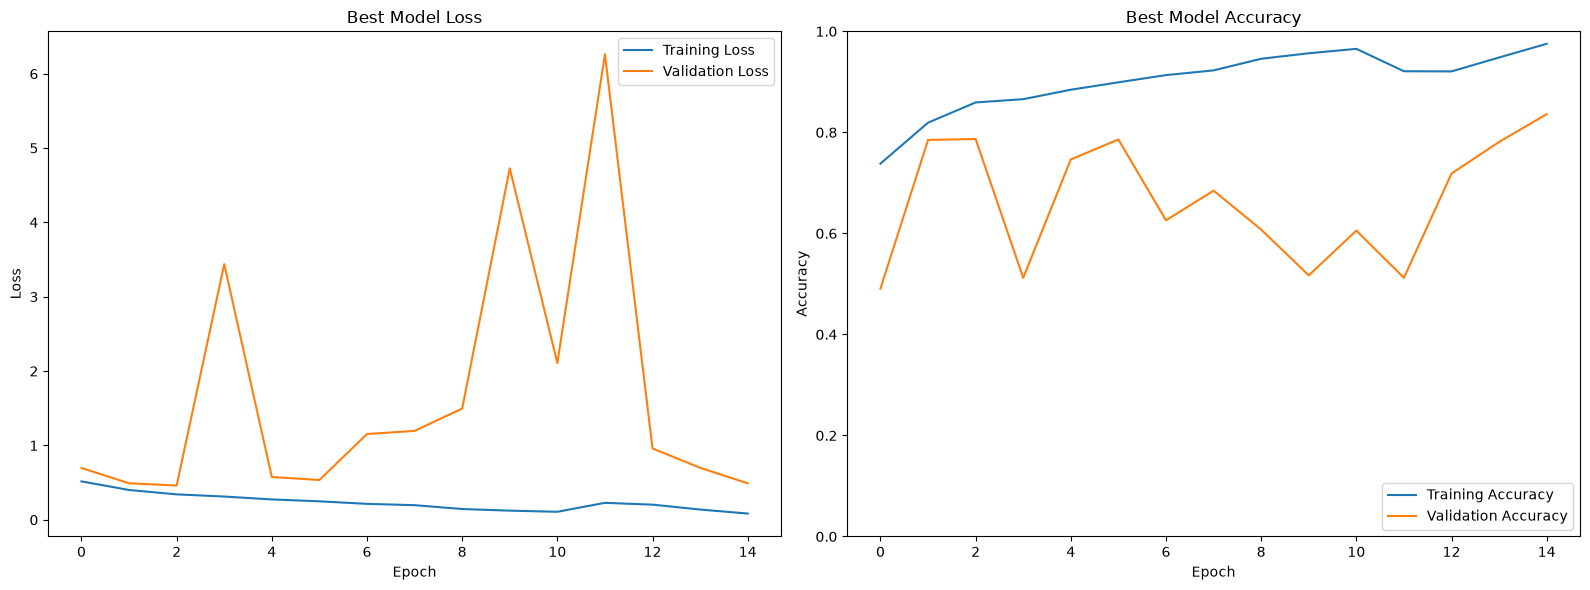

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

axs[0].plot(best_history["train_loss"], label="Training Loss")
axs[0].plot(best_history["val_loss"], label="Validation Loss")
axs[0].set_title("Best Model Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend(loc="upper right")

axs[1].plot(best_history["train_acc"], label="Training Accuracy")
axs[1].plot(best_history["val_acc"], label="Validation Accuracy")
axs[1].set_title("Best Model Accuracy")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].set_ylim(0, 1)
axs[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

/var/folders/j2/ly_gk9s162l3tbyb8nfbcdsm0000gn/T/ipykernel_5438/2027927038.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


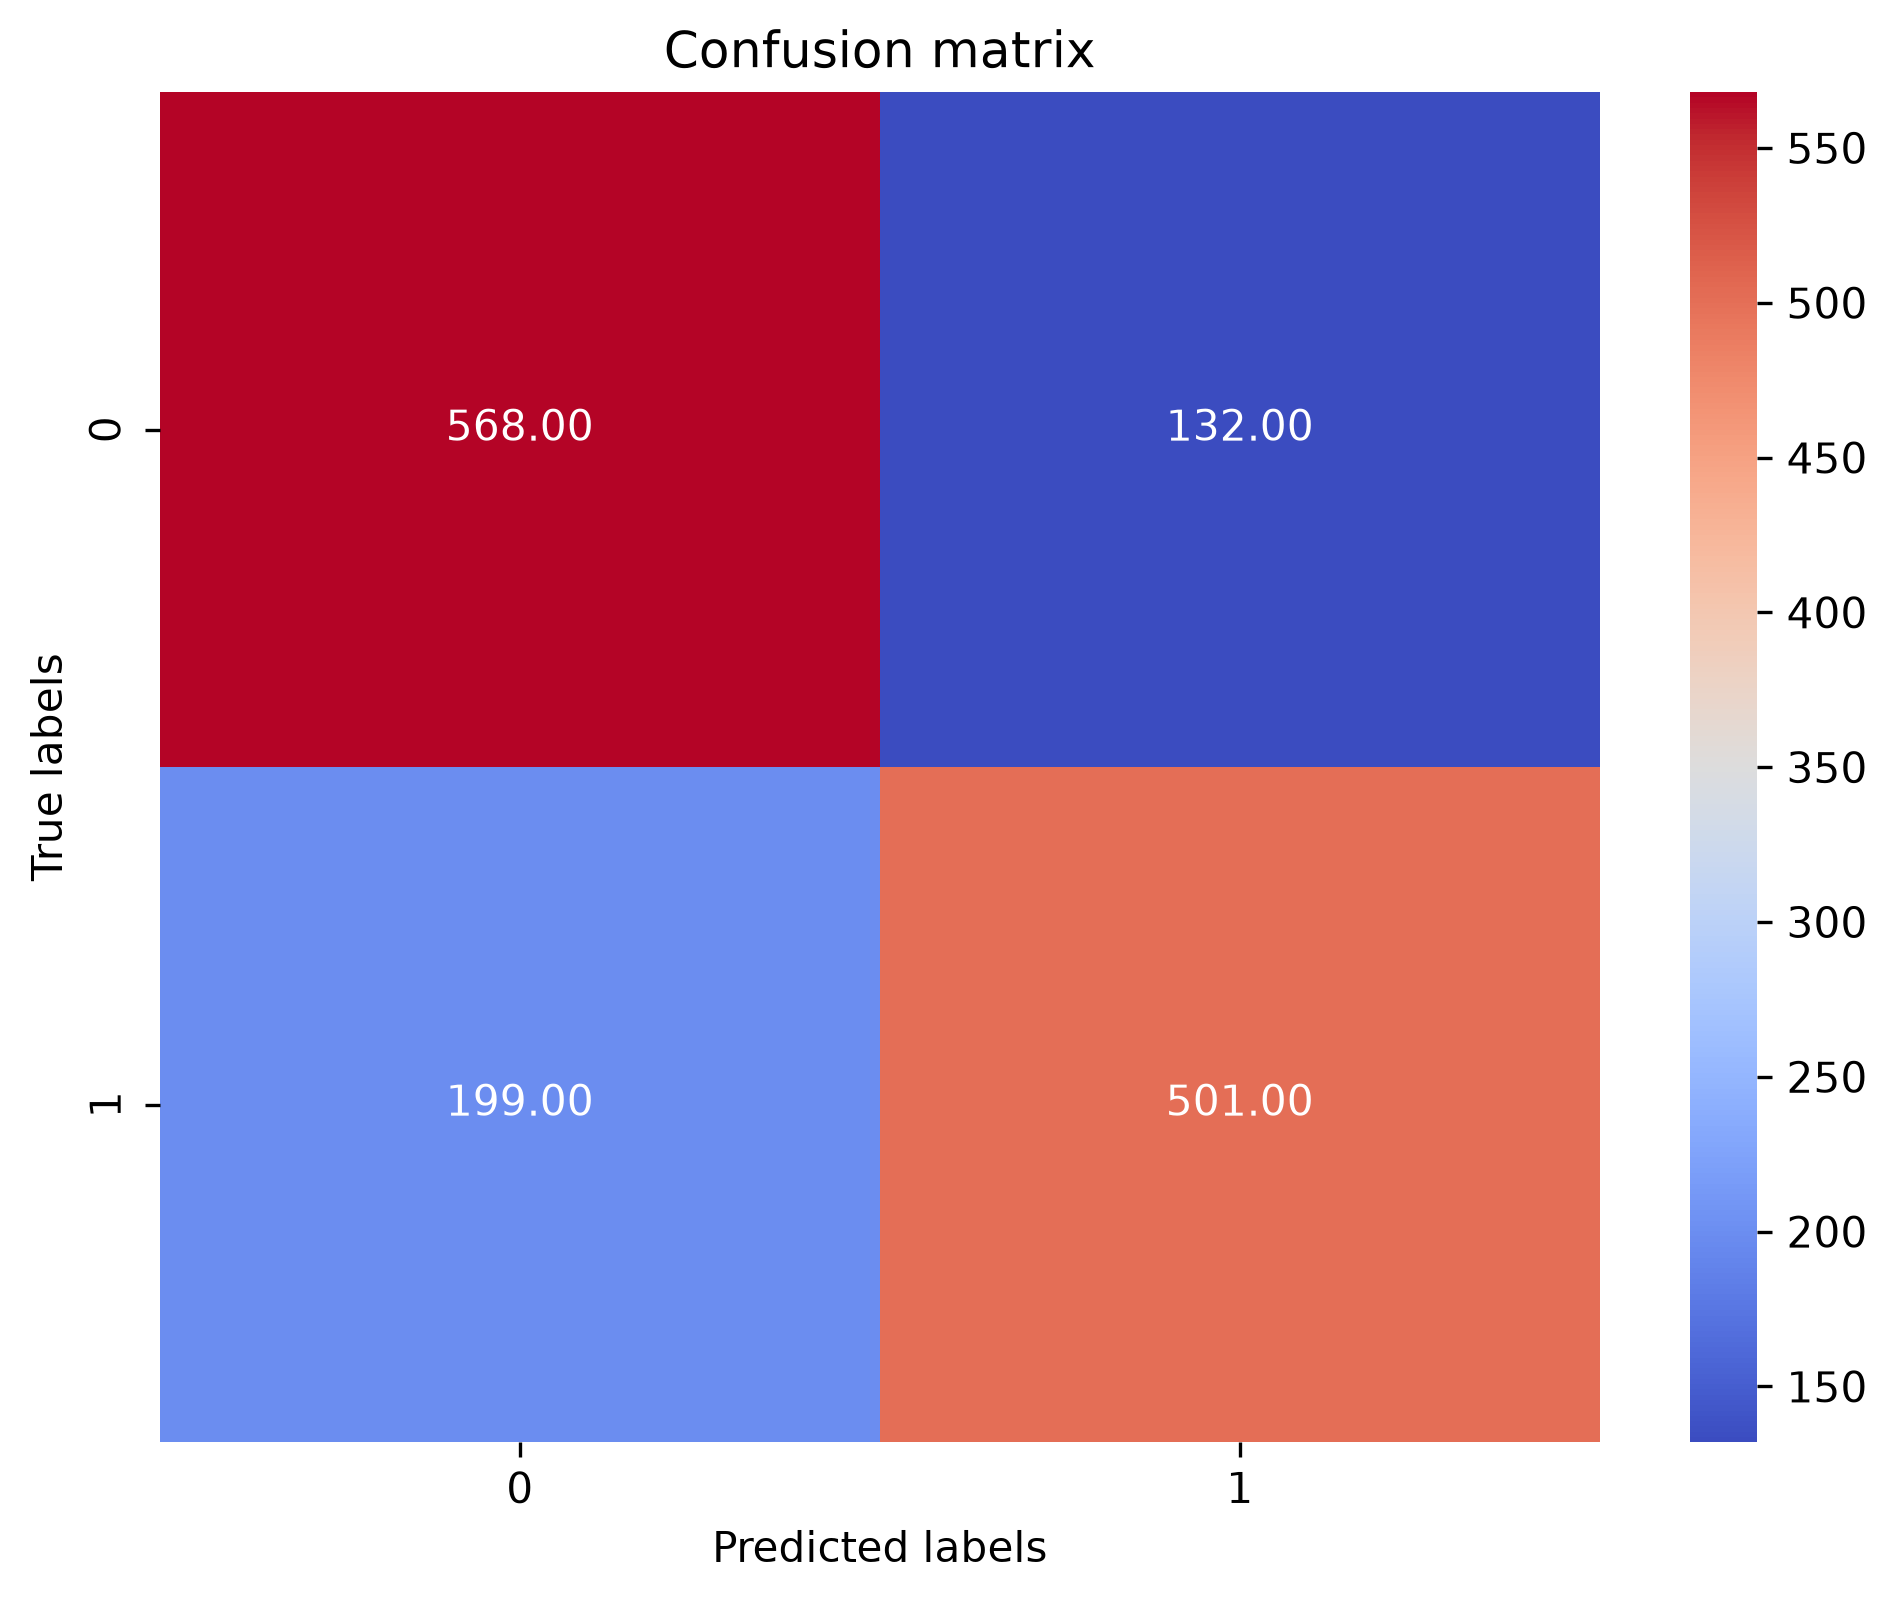

In [36]:
y_true = np.array( test_politics_df['label'].to_numpy(), dtype=np.long()).ravel()
y_pred = []
for pred_element in predictions:
    for p in pred_element:
        y_pred.append(int(p))

matrix = confusion_matrix(y_true, y_pred)

fig = plt.figure(figsize=[6, 4.5], dpi=300)
ax = fig.add_axes([0,0,1,1])
sns.heatmap(matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Confusion matrix')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.tight_layout()
plt.show()